<a href="https://colab.research.google.com/github/keonU206/Computer/blob/main/%EC%9D%B4%EC%82%B0%EC%88%98%ED%95%9909_%EA%B7%B8%EB%9E%98%ED%94%84%EA%B3%BC%EC%A0%9C_202321603_%EA%B9%80%EA%B1%B4%EC%9A%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 이산수학 08 그래프 실습 과제
### DFS · BFS · 친구 추천 → 감염 시뮬레이션 확장

| 항목 | 내용 |
|---|---|
| 학번 / 이름 | 202321603 / 김건우 |
| 실행 환경 | Google Colab (Python 3) |
| 사용 AI 서비스 | Claude Opus 5.5 (Anthropic) — 과제 3, 4 바이브 코딩 |

| 과제 | 내용 | 위치 |
|:-:|---|---|
| 1 | `graph`를 팀원과 팀원 친구 이름으로 바꿔서 실습 | 1장 |
| 2 | DFS와 BFS 탐색 순서를 손으로 써본 후 비교 | 2장 |
| 3 | (바이브 코딩)(선택) networkx로 시각화 | 3장 |
| 4 | (바이브 코딩) 감염 시뮬레이션: 2단계 이내 전염 경로 추적 + 테스트 케이스(하/중/상) | 4장 |

> 실행 방법: `런타임 → 모두 실행` (Ctrl+F9)

---
## 0. 실행 환경 준비
그래프 그림에 한글 이름이 깨지지 않도록 나눔폰트를 설치하고 matplotlib에 등록합니다.

In [30]:
import os, glob, subprocess
FONT_PATH = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if not os.path.exists(FONT_PATH):          # Colab: 나눔폰트 설치
    subprocess.run('apt-get -qq install -y fonts-nanum', shell=True, capture_output=True, timeout=180)
if not os.path.exists(FONT_PATH):          # 설치가 안 되는 환경이면 시스템의 다른 한글 폰트 사용
    FONT_PATH = (glob.glob('/usr/share/fonts/**/*Nanum*.ttf', recursive=True) +
                 sorted(glob.glob('/usr/share/fonts/**/*CJK*Regular*', recursive=True), key=lambda f: 'Sans' not in f))[0]

import random, time
from collections import deque
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import networkx as nx

fm.fontManager.addfont(FONT_PATH)
FONT_NAME = fm.FontProperties(fname=FONT_PATH).get_name()
plt.rc('font', family=FONT_NAME)
plt.rc('axes', unicode_minus=False)
print('한글 폰트:', FONT_NAME, '/ networkx', nx.__version__)

한글 폰트: NanumGothic / networkx 3.7


---
## 1. [과제 1] 우리 조 그래프로 바꿔서 실습

수업 예시(`'Alice': ['Bob', 'Charlie'] …`)와 같은 **인접 리스트(딕셔너리)** 구조에 우리 조 팀원과 팀원 친구 이름을 넣었습니다.

- key = 팀원, value = 그 팀원의 친구 목록 (**방향 그래프**: `A → B`는 "A가 B와 연결")
- key가 없는 사람(예: `최우진`)은 친구 목록 정보가 없는 사람 → `graph.get(v, [])`로 빈 리스트 처리
- `김유진 → 김건우`, `김건우 → 김유진`이 서로 연결되어 **사이클**이 있음 → `visited`가 꼭 필요한 이유
- 그래프가 **3개 그룹**(김건우·김유진 / 이성원 / 홍예영)으로 나뉘어 있어, 전체 탐색은 교재 의사코드의 `DFS(G)`처럼 방문 안 한 노드에서 다시 시작합니다.
- 탐색 시작점은 **김건우**(본인)로 고정하고, 나머지 그룹은 딕셔너리 순서대로 이어서 탐색합니다.

In [31]:
# 우리 조 그래프: 팀원 + 팀원 친구 관계 (인접 리스트)
graph = {
    '김유진': ['양규원', '김건우', '최우진', '이지은', '송광현'],
    '양규원': ['최우진', '정우찬', '전소은', '민다온'],
    '이성원': ['이지현', '김세찬', '신재호', '문성준', '신동훈'],
    '김건우': ['김유진', '김준성', '심상묵', '박건우', '배동성'],
    '홍예영': ['김윤서', '홍서연', '전한나', '정지우']
}

START = '김건우'   # 탐색 시작점 (본인)

ALL_NODES = list(dict.fromkeys(list(graph) + [v for vs in graph.values() for v in vs]))
print(f"사람 수: {len(ALL_NODES)}명, 연결(간선) 수: {sum(len(v) for v in graph.values())}개\n")
for person, friends in graph.items():
    print(f"  {person} → {', '.join(friends)}")

사람 수: 24명, 연결(간선) 수: 23개

  김유진 → 양규원, 김건우, 최우진, 이지은, 송광현
  양규원 → 최우진, 정우찬, 전소은, 민다온
  이성원 → 이지현, 김세찬, 신재호, 문성준, 신동훈
  김건우 → 김유진, 김준성, 심상묵, 박건우, 배동성
  홍예영 → 김윤서, 홍서연, 전한나, 정지우


### 1-1. DFS (수업 코드 + 전체 탐색)
교재 의사코드의 `dfs(G, v)`와 `DFS(G)`를 그대로 옮겼습니다. 시작점(김건우)부터 탐색하고, 연결되지 않은 그룹은 이어서 탐색합니다.

In [32]:
def dfs(graph, v, visited):
    visited.add(v)                         # 방문 표시
    print(v, end=' ')                      # 방문 순서 출력 (공백으로 구분)
    for neighbor in graph.get(v, []):      # key가 없는 사람은 빈 리스트
        if neighbor not in visited:        # 아직 안 간 친구면
            dfs(graph, neighbor, visited)  #   그 친구 쪽으로 끝까지 내려감 (재귀)

def DFS_all(graph, start):
    visited = set()
    for u in [start] + list(graph):        # 시작점 먼저, 나머지는 딕셔너리 순서
        if u not in visited:
            print('\n  [그룹 시작:', u, ']', end='  ')
            dfs(graph, u, visited)

print("DFS 탐색 순서:", end='')
DFS_all(graph, START)

DFS 탐색 순서:
  [그룹 시작: 김건우 ]  김건우 김유진 양규원 최우진 정우찬 전소은 민다온 이지은 송광현 김준성 심상묵 박건우 배동성 
  [그룹 시작: 이성원 ]  이성원 이지현 김세찬 신재호 문성준 신동훈 
  [그룹 시작: 홍예영 ]  홍예영 김윤서 홍서연 전한나 정지우 

### 1-2. BFS (수업 코드 + 전체 탐색)

In [33]:
from collections import deque   # 큐(Queue)를 효율적으로 구현할 수 있는 도구

def bfs(graph, start, visited):
    queue = deque([start])
    visited.add(start)
    while queue:
        v = queue.popleft()                # 먼저 들어온 사람부터 꺼냄 (FIFO)
        print(v, end=' ')
        for neighbor in graph.get(v, []):
            if neighbor not in visited:
                visited.add(neighbor)      # 넣을 때 방문 표시 → 중복 방지
                queue.append(neighbor)

def BFS_all(graph, start):
    visited = set()
    for u in [start] + list(graph):
        if u not in visited:
            print('\n  [그룹 시작:', u, ']', end='  ')
            bfs(graph, u, visited)

print("BFS 탐색 순서:", end='')
BFS_all(graph, START)

BFS 탐색 순서:
  [그룹 시작: 김건우 ]  김건우 김유진 김준성 심상묵 박건우 배동성 양규원 최우진 이지은 송광현 정우찬 전소은 민다온 
  [그룹 시작: 이성원 ]  이성원 이지현 김세찬 신재호 문성준 신동훈 
  [그룹 시작: 홍예영 ]  홍예영 김윤서 홍서연 전한나 정지우 

### 1-3. 친구 추천 (수업 코드 그대로)
2단계 거리 친구(내 친구의 친구)만 추천하고, 직접 연결된 친구는 제외합니다.

In [34]:
def recommend_friend(graph, start):
    visited = set()
    queue = deque([(start, 0)])  # (노드, 거리)

    print(f"\n{start}의 친구 추천 (2단계):")

    while queue:
        current, depth = queue.popleft()
        if current not in visited:
            visited.add(current)
            if depth == 2:
                print("-", current)
            if depth < 2:
                for neighbor in graph.get(current, []):
                    queue.append((neighbor, depth + 1))

recommend_friend(graph, '김건우')
recommend_friend(graph, '김유진')


김건우의 친구 추천 (2단계):
- 양규원
- 최우진
- 이지은
- 송광현

김유진의 친구 추천 (2단계):
- 정우찬
- 전소은
- 민다온
- 김준성
- 심상묵
- 박건우
- 배동성


---
## 2. [과제 2] DFS와 BFS 탐색 순서를 손으로 써본 후 비교

- 시작점 = **김건우**, 이웃은 리스트에 **적힌 순서대로** 확인
- 아래 표는 김건우 그룹(13명) 기준이고, 이성원·홍예영 그룹은 시작점의 친구 순서대로 방문하므로 DFS와 BFS 결과가 같습니다.

### 2-1. DFS 손 추적 (재귀 호출 스택)

| 단계 | 현재 | 확인하는 이웃 | 판단 | 호출 스택 (아래→위) | 방문 순서 |
|:-:|:-:|:-:|---|---|:-:|
| 1 | 김건우 | – | 방문 | 김건우 | **1** 김건우 |
| 2 | 김건우 | 김유진 | 미방문 → 내려감 | 김건우, 김유진 | **2** 김유진 |
| 3 | 김유진 | 양규원 | 미방문 → 내려감 | 김건우, 김유진, 양규원 | **3** 양규원 |
| 4 | 양규원 | 최우진 | 미방문 → 내려감 | …, 양규원, 최우진 | **4** 최우진 |
| 5 | 최우진 | (친구 정보 없음) | 막다른 길 → 복귀 | …, 양규원 | |
| 6 | 양규원 | 정우찬 | 미방문 → 내려감 → 복귀 | …, 양규원 | **5** 정우찬 |
| 7 | 양규원 | 전소은 | 미방문 → 내려감 → 복귀 | …, 양규원 | **6** 전소은 |
| 8 | 양규원 | 민다온 | 미방문 → 내려감 → 복귀 | …, 양규원 | **7** 민다온 |
| 9 | 양규원 | (끝) | 복귀 | 김건우, 김유진 | |
| 10 | 김유진 | 김건우 | **이미 방문** (사이클) → 건너뜀 | 김건우, 김유진 | |
| 11 | 김유진 | 최우진 | **이미 방문** → 건너뜀 | 김건우, 김유진 | |
| 12 | 김유진 | 이지은 | 미방문 → 내려감 → 복귀 | 김건우, 김유진 | **8** 이지은 |
| 13 | 김유진 | 송광현 | 미방문 → 내려감 → 복귀 | 김건우, 김유진 | **9** 송광현 |
| 14 | 김유진 | (끝) | 복귀 | 김건우 | |
| 15 | 김건우 | 김준성 · 심상묵 · 박건우 · 배동성 | 차례로 방문 → 복귀 | 김건우 | **10~13** |
| 16 | 김건우 | (끝) | 그룹 종료 → 다음 그룹 이성원 | (비어 있음) | |

**DFS 결과 (김건우 그룹):** 김건우 → 김유진 → 양규원 → 최우진 → 정우찬 → 전소은 → 민다온 → 이지은 → 송광현 → 김준성 → 심상묵 → 박건우 → 배동성

### 2-2. BFS 손 추적 (큐)

| 단계 | 꺼냄 (dequeue) | 새로 넣음 (enqueue) | 큐 상태 (앞 ← → 뒤) | 방문 순서 |
|:-:|:-:|---|---|:-:|
| 0 | – | 김건우 | [김건우] | |
| 1 | 김건우 | 김유진, 김준성, 심상묵, 박건우, 배동성 | [김유진, 김준성, 심상묵, 박건우, 배동성] | **1** |
| 2 | 김유진 | 양규원, 최우진, 이지은, 송광현 (김건우는 이미 방문) | [김준성, 심상묵, 박건우, 배동성, 양규원, 최우진, 이지은, 송광현] | **2** |
| 3~6 | 김준성, 심상묵, 박건우, 배동성 | (친구 정보 없음) | [양규원, 최우진, 이지은, 송광현] | **3~6** |
| 7 | 양규원 | 정우찬, 전소은, 민다온 (최우진은 이미 방문) | [최우진, 이지은, 송광현, 정우찬, 전소은, 민다온] | **7** |
| 8~13 | 최우진, 이지은, 송광현, 정우찬, 전소은, 민다온 | – | [] → 그룹 종료 | **8~13** |

**BFS 결과 (김건우 그룹):** 김건우 → 김유진 → 김준성 → 심상묵 → 박건우 → 배동성 → 양규원 → 최우진 → 이지은 → 송광현 → 정우찬 → 전소은 → 민다온

### 2-3. 손 추적 결과와 코드 실행 결과 비교

In [35]:
def dfs_all_order(graph, start):
    # DFS 방문 순서를 리스트로 반환 (출력 대신 검증용)
    visited, order = set(), []
    def go(v):
        visited.add(v); order.append(v)
        for w in graph.get(v, []):
            if w not in visited:
                go(w)
    for u in [start] + list(graph):
        if u not in visited:
            go(u)
    return order

def bfs_all_order(graph, start):
    # BFS 방문 순서를 리스트로 반환 (검증용)
    visited, order = set(), []
    for u in [start] + list(graph):
        if u in visited:
            continue
        visited.add(u); queue = deque([u])
        while queue:
            v = queue.popleft(); order.append(v)
            for w in graph.get(v, []):
                if w not in visited:
                    visited.add(w); queue.append(w)
    return order

# 손으로 쓴 순서 (김건우 → 이성원 → 홍예영 그룹 순)
hand_dfs = ['김건우', '김유진', '양규원', '최우진', '정우찬', '전소은', '민다온', '이지은', '송광현',
            '김준성', '심상묵', '박건우', '배동성',
            '이성원', '이지현', '김세찬', '신재호', '문성준', '신동훈',
            '홍예영', '김윤서', '홍서연', '전한나', '정지우']
hand_bfs = ['김건우', '김유진', '김준성', '심상묵', '박건우', '배동성', '양규원', '최우진', '이지은',
            '송광현', '정우찬', '전소은', '민다온',
            '이성원', '이지현', '김세찬', '신재호', '문성준', '신동훈',
            '홍예영', '김윤서', '홍서연', '전한나', '정지우']

code_dfs, code_bfs = dfs_all_order(graph, START), bfs_all_order(graph, START)

print(f"{'순서':>4} | {'DFS(손)':^5} {'DFS(코드)':^5} | {'BFS(손)':^5} {'BFS(코드)':^5}")
print('-' * 44)
for i, (a, b, c, d) in enumerate(zip(hand_dfs, code_dfs, hand_bfs, code_bfs), 1):
    mark = '' if (a == b and c == d) else '  ← 불일치'
    print(f"{i:>4} | {a:^6} {b:^7} | {c:^6} {d:^7}{mark}")

assert hand_dfs == code_dfs and hand_bfs == code_bfs
print("\n✅ 손으로 쓴 DFS·BFS 순서와 코드 실행 결과가 24명 모두 일치")

  순서 | DFS(손) DFS(코드) | BFS(손) BFS(코드)
--------------------------------------------
   1 |  김건우     김건우   |  김건우     김건우  
   2 |  김유진     김유진   |  김유진     김유진  
   3 |  양규원     양규원   |  김준성     김준성  
   4 |  최우진     최우진   |  심상묵     심상묵  
   5 |  정우찬     정우찬   |  박건우     박건우  
   6 |  전소은     전소은   |  배동성     배동성  
   7 |  민다온     민다온   |  양규원     양규원  
   8 |  이지은     이지은   |  최우진     최우진  
   9 |  송광현     송광현   |  이지은     이지은  
  10 |  김준성     김준성   |  송광현     송광현  
  11 |  심상묵     심상묵   |  정우찬     정우찬  
  12 |  박건우     박건우   |  전소은     전소은  
  13 |  배동성     배동성   |  민다온     민다온  
  14 |  이성원     이성원   |  이성원     이성원  
  15 |  이지현     이지현   |  이지현     이지현  
  16 |  김세찬     김세찬   |  김세찬     김세찬  
  17 |  신재호     신재호   |  신재호     신재호  
  18 |  문성준     문성준   |  문성준     문성준  
  19 |  신동훈     신동훈   |  신동훈     신동훈  
  20 |  홍예영     홍예영   |  홍예영     홍예영  
  21 |  김윤서     김윤서   |  김윤서     김윤서  
  22 |  홍서연     홍서연   |  홍서연     홍서연  
  23 |  전한나     전한나   |  전한나     전한나  
  24 |  정지우     정지우

### 2-4. DFS vs BFS 비교

| 비교 항목 | DFS (깊이 우선) | BFS (너비 우선) |
|---|---|---|
| 자료구조 | **스택** (재귀 호출) | **큐** (`deque`) |
| 탐색 모양 | 한 친구 쪽으로 **끝까지** 내려간 뒤 되돌아옴 | 가까운 친구부터 **한 겹(레벨)씩** 넓혀 감 |
| 김건우 다음 순서 | 김유진 → **양규원**(2단계) → **최우진**(3단계)으로 바로 내려감 | 김유진 → 김준성 → 심상묵 … **1단계 친구 5명을 먼저** 다 봄 |
| 김준성(1단계)의 방문 순서 | **10번째** (김유진 쪽을 다 본 뒤) | **3번째** |
| 최단 거리 보장 | ✗ | ✔ (처음 발견한 거리 = 최단 거리) |
| 어울리는 문제 | 경로가 있는지, 모든 경우 탐색 | **몇 단계 떨어져 있는지** (친구 추천, 감염 추적) |

**관찰 포인트**
- `최우진`은 김유진(1단계)과 양규원(2단계) 양쪽 친구입니다. DFS는 양규원 쪽으로 먼저 내려가서 **김건우 → 김유진 → 양규원 → 최우진(3번째 줄)** 경로로 처음 만나지만, 김건우와의 실제 거리는 **2단계**(김건우 → 김유진 → 최우진)입니다. BFS는 처음부터 2단계로 정확히 찾습니다.
- 그래서 과제 4의 "2단계 이내 감염 추적"은 **BFS**로 구현합니다.

---
## 3. [과제 3] (바이브 코딩)(선택) networkx로 시각화

- 그룹별로 **레벨(시작점으로부터의 거리)마다 한 줄씩** 배치 → BFS의 "한 겹씩" 구조가 보이도록
- 노드 색 = 레벨, 빨간 번호 = 방문 순서

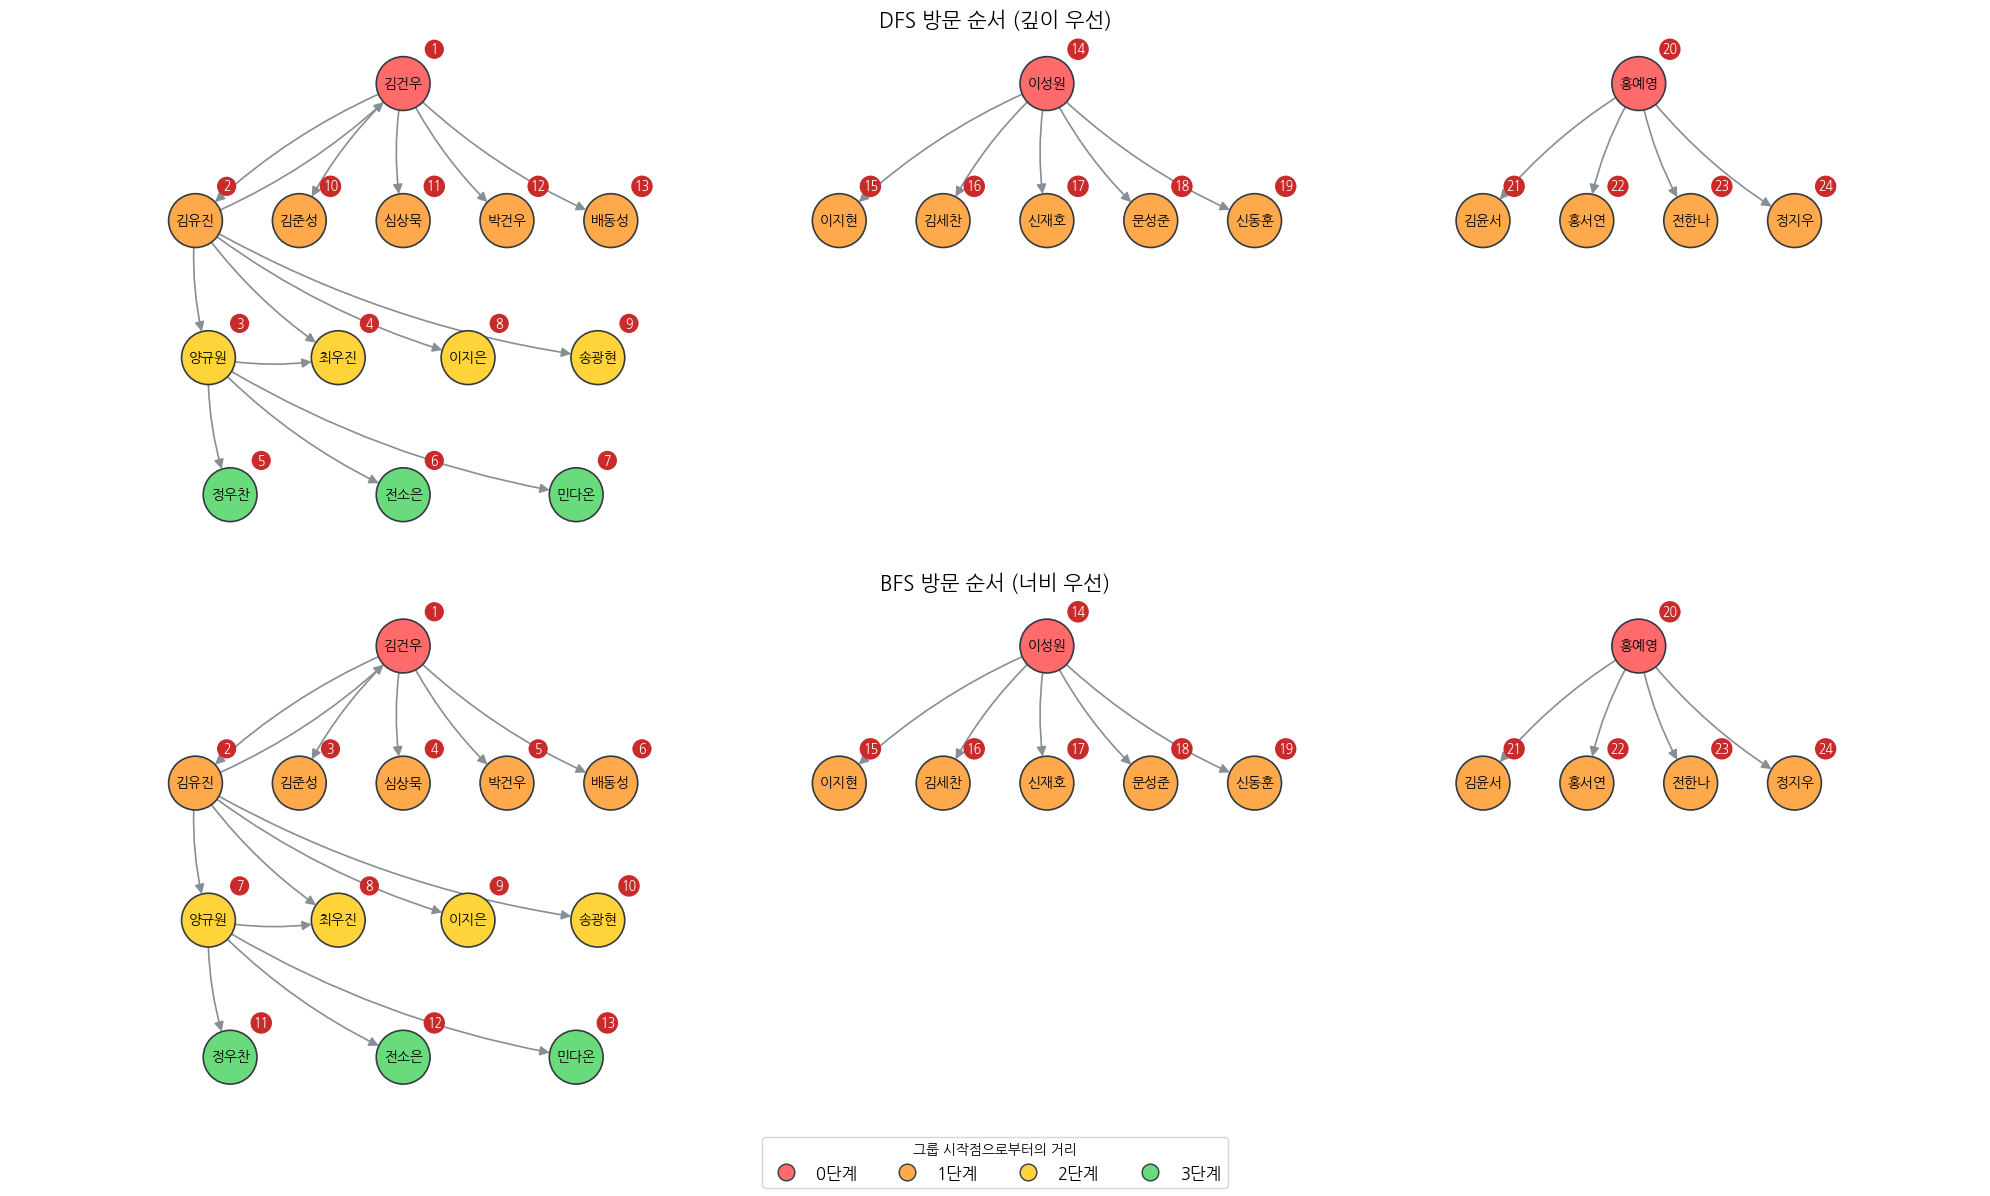

In [36]:
def to_nx(graph):
    # 딕셔너리 인접 리스트 → networkx 방향 그래프
    G = nx.DiGraph()
    G.add_nodes_from(dict.fromkeys(list(graph) + [v for vs in graph.values() for v in vs]))
    for u, vs in graph.items():
        G.add_edges_from((u, v) for v in vs)
    return G

def forest_pos(graph, start, gap=1.2):
    # 그룹마다 BFS 레벨 기준으로 줄을 나누고, 그룹은 가로로 나란히 배치
    G = to_nx(graph)
    seen, pos, level, x0 = set(), {}, {}, 0.0
    for root in [start] + list(G.nodes):
        if root in seen:
            continue
        rows, dist, q = {}, {root: 0}, deque([root]); seen.add(root)
        while q:
            v = q.popleft(); rows.setdefault(dist[v], []).append(v)
            for w in G.successors(v):
                if w not in seen:
                    seen.add(w); dist[w] = dist[v] + 1; q.append(w)
        width = max(len(r) for r in rows.values())
        for lv, row in rows.items():
            for i, n in enumerate(row):
                pos[n] = (x0 + (i + 0.5) * width / len(row), -lv)
                level[n] = lv
        x0 += width + gap
    return pos, level

LEVEL_COLORS = ['#ff6b6b', '#ffa94d', '#ffd43b', '#69db7c', '#4dabf7']

def draw_order(graph, start, order, title, ax):
    G = to_nx(graph)
    pos, level = forest_pos(graph, start)
    colors = [LEVEL_COLORS[min(level[n], 4)] for n in G.nodes]
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowsize=14, node_size=1500,
                           edge_color='#868e96', width=1.2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=1500,
                           edgecolors='#343a40', linewidths=1.2)
    nx.draw_networkx_labels(G, pos, ax=ax, font_family=FONT_NAME, font_size=10, font_weight='bold')
    for i, n in enumerate(order, 1):
        x, y = pos[n]
        ax.text(x + 0.3, y + 0.25, str(i), ha='center', va='center', fontsize=9, color='white',
                fontweight='bold', bbox=dict(boxstyle='circle,pad=0.25', fc='#c92a2a', ec='none'))
    ax.set_title(title, fontsize=15, fontweight='bold')
    ax.margins(0.06); ax.axis('off')

fig, axes = plt.subplots(2, 1, figsize=(20, 12))
draw_order(graph, START, dfs_all_order(graph, START), 'DFS 방문 순서 (깊이 우선)', axes[0])
draw_order(graph, START, bfs_all_order(graph, START), 'BFS 방문 순서 (너비 우선)', axes[1])
handles = [plt.Line2D([], [], marker='o', ls='', markersize=12, color=LEVEL_COLORS[i],
                      markeredgecolor='#343a40', label=f'{i}단계') for i in range(4)]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=12, title='그룹 시작점으로부터의 거리')
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

---
## 4. [과제 4] (바이브 코딩) 감염 시뮬레이션: 2단계 이내 전염 경로 추적

### 요구사항 체크
- [x] 그래프는 **인접 리스트** 형태 (1장의 `graph` 그대로 사용)
- [x] 감염자는 **1명**, **이름으로 지정** → `'김건우'`
- [x] **2단계 이내** 노드 출력, **감염자 자신은 제외**
- [x] 감염 경로의 **거리(레벨)** 함께 표시 + **전염 경로** 출력

### 친구 추천 코드에서 바꾼 부분
| 친구 추천 (수업 코드) | 감염 시뮬레이션 |
|---|---|
| 거리 **2만** 출력 | 거리 **1 ~ max_depth 전부** 출력 ("이내") |
| 큐에 `(노드, 거리)` | 동일 + **`parent`(누구에게서 옮았는지)** 저장 → 경로 복원 |
| **꺼낼 때** 방문 처리 → 같은 사람이 큐에 여러 번 들어감 | **넣을 때** 방문 처리 → 한 사람은 한 번만 (1000명 테스트 대비) |
| 단계 2 고정 | `max_depth` 매개변수 → 테스트에서 10, 50으로 확장 |

> 그래프 방향: 과제 1과 같은 **방향 그래프**로 계산합니다. (`A → B`일 때 A가 B에게 옮김)

In [37]:
def infection_simulation(graph, patient_zero, max_depth=2):
    '''
    BFS로 최초 감염자(patient_zero)로부터 max_depth 단계 이내에 전염되는 사람을 찾는다.
    반환: {이름: (레벨, 전염 경로 리스트)}   ※ 감염자 본인은 제외
    '''
    all_nodes = set(graph) | {v for vs in graph.values() for v in vs}
    if patient_zero not in all_nodes:                 # 그래프에 아예 없는 이름
        raise ValueError(f"'{patient_zero}'은(는) 그래프에 없는 사람입니다.")

    dist   = {patient_zero: 0}        # 방문 여부 + 레벨(거리)
    parent = {patient_zero: None}     # 누구에게서 옮았는지 (경로 복원용)
    queue  = deque([patient_zero])

    while queue:
        cur = queue.popleft()                         # 가까운 사람부터 꺼냄
        if dist[cur] == max_depth:                    # 최대 단계면 더 퍼뜨리지 않음
            continue
        for nxt in graph.get(cur, []):                # 친구 정보가 없으면 빈 리스트
            if nxt not in dist:                       # 처음 감염되는 사람만
                dist[nxt] = dist[cur] + 1             #   레벨 = 옮긴 사람 레벨 + 1
                parent[nxt] = cur                     #   누가 옮겼는지 기록
                queue.append(nxt)

    def path_to(node):                                # parent를 거꾸로 따라가 경로 복원
        path = []
        while node is not None:
            path.append(node)
            node = parent[node]
        return path[::-1]

    return {n: (d, path_to(n)) for n, d in dist.items() if n != patient_zero}


def print_infection(graph, patient_zero, max_depth=2):
    result = infection_simulation(graph, patient_zero, max_depth)
    print(f"🦠 최초 감염자: {patient_zero}  ({max_depth}단계 이내 추적)")
    print('=' * 50)
    if not result:
        print("  전염된 사람 없음")
    for level in range(1, max_depth + 1):
        people = [(n, p) for n, (d, p) in result.items() if d == level]
        if people:
            tag = '직접 접촉' if level == 1 else f'{level}차 전파'
            print(f"\n[레벨 {level}] {tag} - {len(people)}명")
            for name, path in people:
                print(f"   • {name}   경로: {' → '.join(path)}")
    print('=' * 50)
    print(f"총 {len(result)}명 감염 (본인 제외)\n")
    return result

result = print_infection(graph, '김건우', 2)

🦠 최초 감염자: 김건우  (2단계 이내 추적)

[레벨 1] 직접 접촉 - 5명
   • 김유진   경로: 김건우 → 김유진
   • 김준성   경로: 김건우 → 김준성
   • 심상묵   경로: 김건우 → 심상묵
   • 박건우   경로: 김건우 → 박건우
   • 배동성   경로: 김건우 → 배동성

[레벨 2] 2차 전파 - 4명
   • 양규원   경로: 김건우 → 김유진 → 양규원
   • 최우진   경로: 김건우 → 김유진 → 최우진
   • 이지은   경로: 김건우 → 김유진 → 이지은
   • 송광현   경로: 김건우 → 김유진 → 송광현
총 9명 감염 (본인 제외)



### 4-1. 감염 확산 시각화
빨간 굵은 화살표 = 실제 전염 경로, 회색 = 2단계 밖이라 감염되지 않은 사람

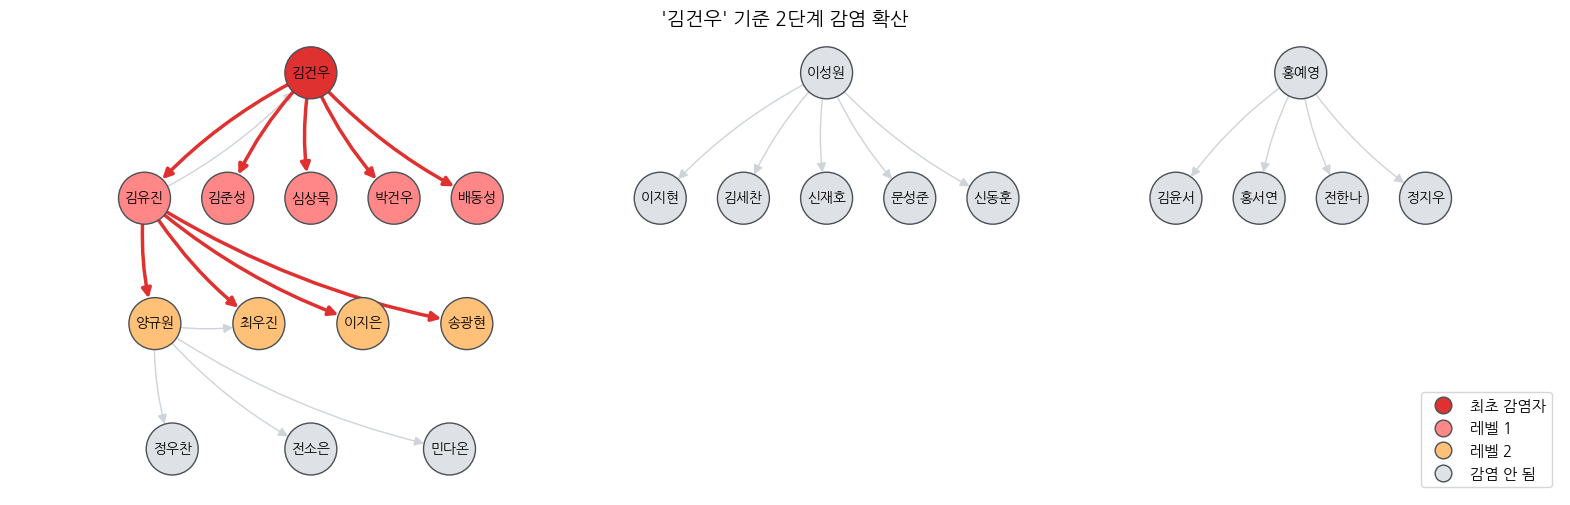

In [38]:
INF_COLORS = {0: '#e03131', 1: '#ff8787', 2: '#ffc078'}

def draw_infection(graph, patient_zero, max_depth=2, ax=None, labels=True, title=None):
    G = to_nx(graph)
    res = infection_simulation(graph, patient_zero, max_depth)
    lv = {patient_zero: 0, **{n: d for n, (d, _) in res.items()}}
    pos, _ = forest_pos(graph, patient_zero)
    colors = [INF_COLORS.get(lv[n], '#ffe066') if n in lv else '#dee2e6' for n in G.nodes]
    tree = {(p[-2], p[-1]) for _, p in res.values()}
    ax = ax or plt.gca()
    size = 1400 if labels else 30
    if labels:
        nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowsize=14, node_size=size,
                               edge_color=['#e03131' if e in tree else '#ced4da' for e in G.edges],
                               width=[2.5 if e in tree else 1 for e in G.edges],
                               connectionstyle='arc3,rad=0.1')
    else:
        nx.draw_networkx_edges(G, pos, ax=ax, arrows=False, alpha=.5, width=.6,
                               edge_color=['#e03131' if e in tree else '#ced4da' for e in G.edges])
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=size,
                           edgecolors='#495057', linewidths=1 if labels else .2)
    if labels:
        nx.draw_networkx_labels(G, pos, ax=ax, font_family=FONT_NAME, font_size=10, font_weight='bold')
    ax.set_title(title or f"'{patient_zero}' 기준 {max_depth}단계 감염 확산", fontsize=14, fontweight='bold')
    ax.axis('off')

plt.figure(figsize=(20, 6))
draw_infection(graph, '김건우', 2)
plt.legend(handles=[plt.Line2D([], [], marker='o', ls='', markersize=12, color=c, markeredgecolor='#495057', label=l)
                    for c, l in [('#e03131', '최초 감염자'), ('#ff8787', '레벨 1'), ('#ffc078', '레벨 2'),
                                 ('#dee2e6', '감염 안 됨')]], loc='lower right', fontsize=11)
plt.show()

---
## 4-2. 테스트 케이스 (하 / 중 / 상)

| 난이도 | 그래프 | max depth | 검증 방법 |
|:-:|---|:-:|---|
| **하** | 우리 조 그래프 (24명, 김건우에게서 퍼질 수 있는 사람 13명) | 2 | 손으로 구한 **정답과 직접 비교** + 경계 상황 5가지 |
| **중** | 생성 그래프 100명 | 10 | `networkx` 최단 거리(정답 라이브러리)와 비교 + 경로 검사 |
| **상** | 생성 그래프 1000명 | 50 | 동일 + 실행 시간 측정 |

공통 검사 함수 `check()`: ① 본인 제외 ② 레벨이 networkx 최단 거리와 같음 ③ 모든 경로가 실제 간선으로 이어져 있음

In [39]:
def check(graph, start, max_depth, label):
    t = time.perf_counter()
    res = infection_simulation(graph, start, max_depth)
    ms = (time.perf_counter() - t) * 1000

    truth = nx.single_source_shortest_path_length(to_nx(graph), start, cutoff=max_depth)
    truth.pop(start)
    assert start not in res,                             '① 감염자 본인이 결과에 포함됨'
    assert {n: d for n, (d, _) in res.items()} == truth, '② 레벨이 networkx 최단 거리와 다름'
    for n, (d, p) in res.items():
        assert p[0] == start and p[-1] == n and len(p) == d + 1
        assert all(b in graph.get(a, []) for a, b in zip(p, p[1:])), f'③ 없는 간선: {p}'

    per_level = {}
    for d, _ in res.values():
        per_level[d] = per_level.get(d, 0) + 1
    n_nodes = len(set(graph) | {v for vs in graph.values() for v in vs})
    print(f"✅ [{label}] 노드 {n_nodes}개, max_depth={max_depth} → 감염 {len(res)}명, "
          f"도달한 최대 레벨 {max(per_level, default=0)}  ({ms:.2f} ms)")
    return res, per_level

### 🟢 테스트 1 (하) : 우리 조 그래프, max depth 2

In [40]:
expected = {   # 손으로 구한 정답 {이름: (레벨, 경로)}
    '김유진': (1, ['김건우', '김유진']),
    '김준성': (1, ['김건우', '김준성']),
    '심상묵': (1, ['김건우', '심상묵']),
    '박건우': (1, ['김건우', '박건우']),
    '배동성': (1, ['김건우', '배동성']),
    '양규원': (2, ['김건우', '김유진', '양규원']),
    '최우진': (2, ['김건우', '김유진', '최우진']),   # 양규원을 거치면 3단계지만, 최단 2단계로 기록
    '이지은': (2, ['김건우', '김유진', '이지은']),
    '송광현': (2, ['김건우', '김유진', '송광현']),
}
assert infection_simulation(graph, '김건우', 2) == expected
check(graph, '김건우', 2, '하')

# 경계 상황
r = infection_simulation(graph, '김유진', 2)                       # ① 사이클: 김유진↔김건우
assert '김유진' not in r and r['김건우'][0] == 1 and r['최우진'][0] == 1
assert infection_simulation(graph, '최우진', 2) == {}               # ② 친구 정보 없는 사람
r = infection_simulation(graph, '홍예영', 2)                       # ③ 2단계 전파가 없는 그룹
assert all(d == 1 for d, _ in r.values()) and len(r) == 4
assert '김건우' not in infection_simulation(graph, '이성원', 2)    # ④ 분리된 그룹으로는 안 퍼짐
assert len(infection_simulation(graph, '김건우', 1)) == 5           # ⑤ max_depth=1이면 직접 접촉만
try:                                                                # ⑥ 없는 이름
    infection_simulation(graph, '홍길동')
except ValueError as e:
    print('✅ 예외 처리:', e)
print('✅ [하] 손 계산 정답 일치 + 경계 상황 6가지 통과')

✅ [하] 노드 24개, max_depth=2 → 감염 9명, 도달한 최대 레벨 2  (0.04 ms)
✅ 예외 처리: '홍길동'은(는) 그래프에 없는 사람입니다.
✅ [하] 손 계산 정답 일치 + 경계 상황 6가지 통과


### 그래프 생성기 (중/상 난이도용)
과제 안내대로 중/상 그래프 생성은 바이브 코딩으로 만들었습니다.

- 사람을 레벨 `0 ~ D`에 나눠 담고(각 레벨 최소 1명), 각 사람은 **바로 윗 레벨**의 누군가와 반드시 연결
- 추가 간선은 "같은 레벨끼리" 또는 "아래 → 위 레벨"만 허용 → **지름길이 없어서 최대 깊이가 정확히 D**
- 그냥 무작위로 연결하면 지름길이 생겨서 depth 50까지 퍼지는 그래프가 거의 안 만들어짐

In [41]:
def make_layered_graph(n_nodes, max_depth, extra=1.0, seed=0):
    rng = random.Random(seed)
    names = [f'P{i:04d}' for i in range(n_nodes)]
    levels = [[names[0]]] + [[names[d]] for d in range(1, max_depth + 1)]   # 레벨마다 1명 보장
    for name in names[max_depth + 1:]:
        levels[rng.randint(1, max_depth)].append(name)

    graph = {n: [] for n in names}
    for d in range(1, max_depth + 1):
        for v in levels[d]:                          # 바로 윗 레벨에서 반드시 1개 연결
            graph[rng.choice(levels[d - 1])].append(v)
    level_of = {v: d for d, vs in enumerate(levels) for v in vs}
    for _ in range(int(n_nodes * extra)):            # 지름길이 아닌 추가 연결
        u, v = rng.sample(names, 2)
        if level_of[v] <= level_of[u] + 1 and v not in graph[u]:
            graph[u].append(v)
    return graph, names[0]

### 🟡 테스트 2 (중) : 노드 100개, max depth 10

In [42]:
graph_mid, p0_mid = make_layered_graph(100, 10, seed=42)
res_mid, lv_mid = check(graph_mid, p0_mid, 10, '중')
_ = check(graph_mid, p0_mid, 2, '중 · 2단계만')

far = max(res_mid, key=lambda n: res_mid[n][0])
print(f"\n가장 먼 감염자: {far} (레벨 {res_mid[far][0]})  경로: {' → '.join(res_mid[far][1])}")

✅ [중] 노드 100개, max_depth=10 → 감염 99명, 도달한 최대 레벨 10  (0.39 ms)
✅ [중 · 2단계만] 노드 100개, max_depth=2 → 감염 24명, 도달한 최대 레벨 2  (0.10 ms)

가장 먼 감염자: P0020 (레벨 10)  경로: P0000 → P0012 → P0082 → P0039 → P0071 → P0037 → P0045 → P0058 → P0055 → P0018 → P0020


### 🔴 테스트 3 (상) : 노드 1000개, max depth 50

In [43]:
graph_hard, p0_hard = make_layered_graph(1000, 50, seed=2026)
res_hard, lv_hard = check(graph_hard, p0_hard, 50, '상')

far = max(res_hard, key=lambda n: res_hard[n][0])
d, p = res_hard[far]
print(f"\n가장 먼 감염자: {far} (레벨 {d})")
print('경로:', ' → '.join(p[:4]), '→ … →', ' → '.join(p[-3:]))

✅ [상] 노드 1000개, max_depth=50 → 감염 999명, 도달한 최대 레벨 50  (3.86 ms)

가장 먼 감염자: P0833 (레벨 50)
경로: P0000 → P0274 → P0613 → P0317 → … → P0472 → P0938 → P0833


### 📊 테스트 결과 한눈에 보기

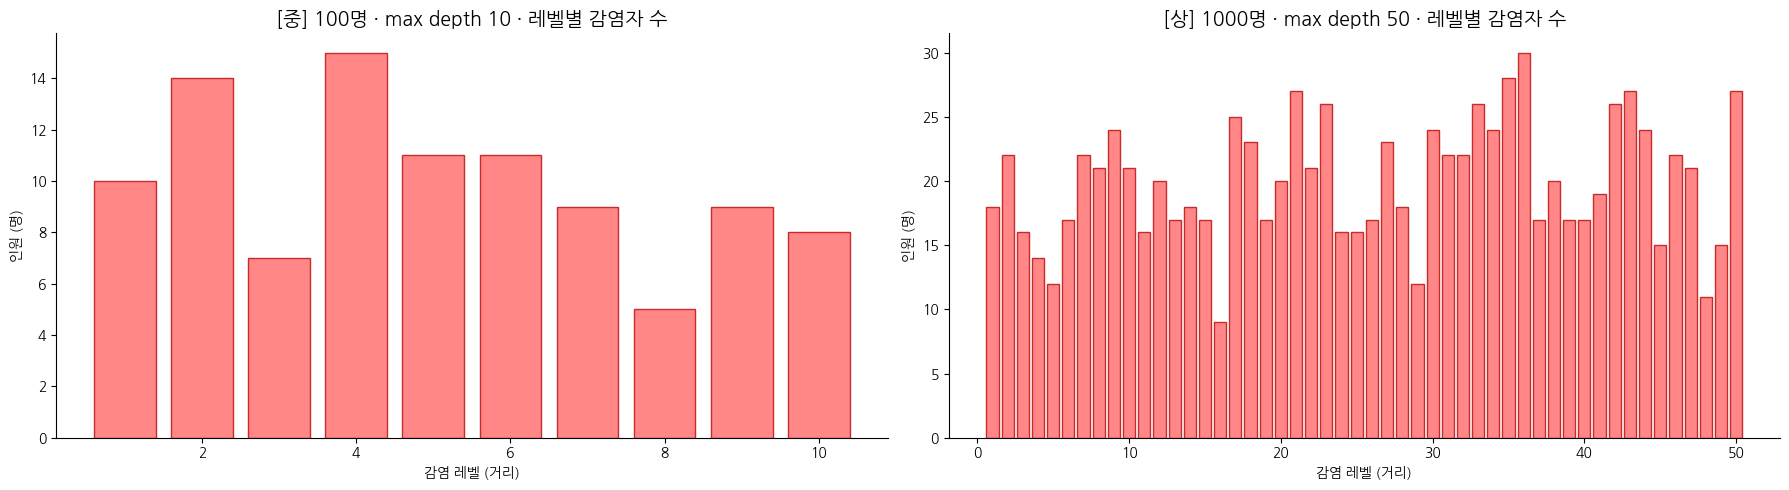

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, lv, title in [(axes[0], lv_mid, '[중] 100명 · max depth 10'),
                      (axes[1], lv_hard, '[상] 1000명 · max depth 50')]:
    ks = sorted(lv)
    ax.bar(ks, [lv[k] for k in ks], color='#ff8787', edgecolor='#c92a2a')
    ax.set_title(title + ' · 레벨별 감염자 수', fontsize=14, fontweight='bold')
    ax.set_xlabel('감염 레벨 (거리)'); ax.set_ylabel('인원 (명)')
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

---
## 🤖 바이브 코딩 사용 명시

| 항목 | 내용 |
|---|---|
| **사용 AI 서비스** | Claude Opus 5.5 (Anthropic) |
| **AI 사용 범위** | 과제 3 (networkx 시각화), 과제 4 (감염 시뮬레이션 함수, 테스트 케이스, 중/상 그래프 생성기) |
| **직접 한 부분** | 과제 1 우리 조 그래프 구성, 과제 2 DFS·BFS 손 추적과 비교 |


